# Real-World Online Retail Data Cleaning & Feature Engineering
## Devixo Solutions — Data Science Internship Task 02

**Author:** Muhammad Awais Bacha  
**Organization:** Devixo Solutions  
**Domain:** Data Science  
**Task Number:** Task 02  
**Repository:** `online-retail-data-cleaning-feature-engineering`  
**License:** Creative Commons Attribution 4.0 International (CC BY 4.0)

---

### Project Overview
In real-world e-commerce platforms, transaction logs are notoriously noisy. Unhandled missing customer identities, accounting bad-debt write-offs, product cancellations, returns, and inventory adjustments frequently distort downstream analytics and machine learning models.

This notebook implements an enterprise-grade, portfolio-quality Data Science pipeline that cleans, explores, engineers features, and models transactions from the canonical **UCI Online Retail** dataset. Every decision is grounded in commercial domain logic, robust statistical methodology, and rigorous code design.

## 2. Project Objectives

The core objectives of this project are:
1. **Initial Dataset Audit:** Thoroughly inspect raw transactional records, column data types, and anomalies.
2. **Missing Value Strategy:** Statistically investigate missing `Description` and `CustomerID` values and implement justified handling strategies.
3. **Deduplication:** Detect and remove exact duplicate rows while reporting before-and-after counts.
4. **Outlier Detection:** Apply both Parametric (Z-Score) and Non-Parametric (IQR) fences on `Quantity`, `UnitPrice`, and `TotalAmount`.
5. **Data Type Correction:** Cast transactional dates, integers, floats, and preserve alphanumeric identifiers.
6. **Feature Engineering:** Create at least 8 (here 14) meaningful temporal, behavioral, and aggregation features without data leakage.
7. **Descriptive Statistics:** Generate statistical comparison tables comparing pre- and post-cleaning metrics.
8. **Automated ML Preprocessing Pipeline:** Construct a reusable Scikit-Learn `Pipeline` with `ColumnTransformer`, `StandardScaler`, and `OneHotEncoder`.
9. **Data Visualizations:** Produce 14 publication-quality visualizations using Matplotlib and Seaborn.
10. **Commercial Business Insights:** Extract actionable e-commerce intelligence on product demand, country revenue, order values, cancellations, and Pareto revenue concentration.

## 3. Problem Statement

Raw e-commerce datasets capture human behavior and automated system events. In the UCI Online Retail dataset:
- Approximately **24.9% of transactions lack a CustomerID**, representing unregistered guest checkouts or point-of-sale terminal entries.
- Over **10,600 transactions have negative quantities**, representing customer cancellations, product returns, or administrative stock adjustments.
- Transactions contain **zero or negative unit prices**, including accounting adjustments (`Adjust bad debt` at -£11,062.06) and damaged warehouse items.
- Naively deleting all rows with missing values or negative quantities discards valuable commercial transaction history and distorts sales volume. Conversely, leaving raw data uncleaned invalidates predictive models.

Our goal is to build a structured, reproducible pipeline that resolves these data quality challenges while preserving business integrity.

## 4. Dataset Source & Attribution

- **Dataset Name:** Online Retail Dataset
- **Repository:** UCI Machine Learning Repository
- **Dataset DOI:** [10.24432/C5BW33](https://doi.org/10.24432/C5BW33)
- **Donor:** Dr. Daqing Chen, Director of Public Policy and Management Research Group, School of Engineering, London South Bank University, London SE1 0AA, UK.
- **License:** Creative Commons Attribution 4.0 International (CC BY 4.0).
- **Timeframe:** 01/12/2010 to 09/12/2011 (1 year of transactions).
- **Commercial Context:** A UK-based registered non-store online retailer primarily selling unique all-occasion giftware. Many customers are wholesalers.

## 5. Import Libraries and Environment Setup

We import standard numerical and data science libraries along with our custom modular Python package developed in `src/`.

In [1]:
import sys
import os
from pathlib import Path

# Add project root to sys.path
PROJECT_ROOT = Path.cwd()
for candidate in [Path.cwd(), Path.cwd().parent]:
    if (candidate / "src").exists():
        PROJECT_ROOT = candidate.resolve()
        break
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Import project modules
from src.config import (
    RAW_DATA_FILE,
    CLEANED_DATA_FILE,
    FEATURE_ENGINEERED_FILE,
    POSITIVE_SALES_FILE,
    PIPELINE_FILE,
    FIGURES_DIR,
    CURRENCY_SYMBOL,
)
from src.data_loader import load_raw_data, get_file_info
from src.data_exploration import (
    basic_info,
    missing_value_analysis,
    duplicate_analysis,
    date_range_analysis,
    negative_quantity_analysis,
    zero_negative_price_analysis,
    cancellation_analysis,
    country_analysis,
)
from src.data_cleaning import (
    clean_retail_data,
    compute_detailed_statistics,
    generate_before_after_comparison,
    investigate_missing_data,
)
from src.outlier_detection import analyze_outliers, get_outlier_summary, flag_outliers
from src.feature_engineering import engineer_all_features, validate_features, get_feature_descriptions
from src.preprocessing_pipeline import train_test_pipeline_workflow, load_pipeline, transform_data, get_feature_names
from src.business_analysis import (
    get_top_products,
    get_top_countries,
    get_monthly_sales_trends,
    calculate_average_order_value,
    analyze_cancellations,
    analyze_product_returns,
    analyze_customer_frequency,
    analyze_revenue_distribution,
)

# Plotting configuration
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 10
print("Environment and modules successfully imported.")

Environment and modules successfully imported.


## 6. Dataset Loading

We load the downloaded original UCI Online Retail dataset. File metadata is verified before loading.

In [2]:
# Inspect raw file metadata
file_info = get_file_info(RAW_DATA_FILE)
print("File Information:")
for k, v in file_info.items():
    print(f"  {k:15s}: {v}")

# Load raw dataset (uses fast interim cache if present)
df_raw = load_raw_data(RAW_DATA_FILE, use_cache=True)
print(f"\nLoaded raw dataset shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
df_raw.head(5)

File Information:
  file_path      : E:\Awais_Document\Devixo Solution internship\Real-World Online Retail Data Cleaning & Feature Engineering\data\raw\Online Retail.xlsx
  file_size_mb   : 22.62
  sheet_names    : ['Online Retail']
  shape          : (541909, 8)
Loading data from: E:\Awais_Document\Devixo Solution internship\Real-World Online Retail Data Cleaning & Feature Engineering\data\raw\Online Retail.xlsx


Dataset loaded successfully — shape: (541909, 8)
  Rows   : 541,909
  Columns: 8

Loaded raw dataset shape: 541,909 rows × 8 columns


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 7. Initial Exploration & Column Understanding

We inspect column data types, memory footprint, and display the primary data dictionary.

In [3]:
# Basic dataset information
info = basic_info(df_raw)
print(f"Memory Usage: {info['memory_usage_mb']:.2f} MB")

BASIC DATASET INFORMATION
Shape          : 541,909 rows × 8 columns
Memory usage   : 126.18 MB

Column data types:
  InvoiceNo            object
  StockCode            object
  Description          object
  Quantity             int64
  InvoiceDate          datetime64[us]
  UnitPrice            float64
  CustomerID           float64
  Country              str
Memory Usage: 126.18 MB


### Data Dictionary

| Column Name | Business Meaning | Original Type | Target Type | Business Importance | Cleaning Decisions |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **InvoiceNo** | 6-digit transaction invoice identifier. 'C' indicates cancellation. | `object` | `str` | Primary key for basket & order aggregation. | Preserved as string to retain leading characters and 'C' cancellation flags. |
| **StockCode** | 5-digit product code, optionally followed by an alphabetical letter. | `object` | `str` | SKU identifier for catalog tracking and demand forecasting. | Whitespace trimmed; strings preserved. Special codes analyzed. |
| **Description** | Product nominal name / commercial description. | `object` | `str` | Item identification, customer search, and text analytics. | Whitespace stripped, casing standardized to uppercase. Missing values investigated. |
| **Quantity** | Quantities of each product per transaction line. | `int64` | `int64` | Demand volume, inventory replenishment, sales volume. | Negative quantities analyzed (cancellations vs damaged adjustments). |
| **InvoiceDate** | Date and time when each transaction was generated. | `datetime64` | `datetime64[ns]` | Time-series forecasting, seasonality, customer recency. | Converted to proper datetime; temporal features extracted. |
| **UnitPrice** | Product unit price in Sterling (£ GBP). | `float64` | `float64` | Revenue calculation, basket value, price tiering. | Negative prices (bad debt) and zero prices (adjustments) removed. |
| **CustomerID** | 5-digit integral customer identifier. | `float64` | `str` / `object` | Customer segmentation, RFM analysis, repeat purchase rate. | Decimals removed (17850.0 -> '17850'); missing handled as 'Unknown'. |
| **Country** | Name of country where each customer resides. | `object` | `str` / `category` | Geographic segmentation and cross-border trade analysis. | Normalized and stripped of trailing whitespace. |

## 8. Data Quality Assessment

We compute summary metrics on missingness, duplicates, date spans, negative quantities, zero prices, and cancellations.

In [4]:
dr = date_range_analysis(df_raw)
nq = negative_quantity_analysis(df_raw)
zp = zero_negative_price_analysis(df_raw)
ca = cancellation_analysis(df_raw)

print(f"Date Range          : {dr['min_date']} to {dr['max_date']} ({dr['span_days']} days)")
print(f"Negative Quantities : {nq['count']:,} rows ({nq['percent']}%)")
print(f"Zero Unit Prices    : {zp['zero_price_count']:,} rows ({zp['zero_price_percent']}%)")
print(f"Negative Unit Prices: {zp['negative_price_count']:,} rows ({zp['negative_price_percent']}%)")
print(f"Cancellations ('C') : {ca['cancellation_count']:,} rows ({ca['cancellation_percent']}%)")

Date Range          : 2010-12-01 08:26:00 to 2011-12-09 12:50:00 (373 days)
Negative Quantities : 10,624 rows (1.96%)
Zero Unit Prices    : 2,515 rows (0.46%)
Negative Unit Prices: 2 rows (0.0%)
Cancellations ('C') : 9,288 rows (1.71%)


## 9. Missing-Value Analysis & Investigation

Missing values in e-commerce transactional data must not be imputed arbitrarily. We analyze the root cause of missing entries in `Description` and `CustomerID`.

In [5]:
# Missing values table
mv_table = missing_value_analysis(df_raw)
display(mv_table)

# In-depth investigation
findings = investigate_missing_data(df_raw)
print("\nMissing Value Findings:")
for k, v in findings.items():
    print(f"  {k:36s}: {v}")

,Column,MissingCount,MissingPercent,TotalRows
0,CustomerID,135080,24.93,541909
1,Description,1454,0.27,541909



Missing Value Findings:
  missing_description_count           : 1454
  missing_description_zero_price_count: 1454
  missing_description_zero_price_pct  : 100.0
  missing_customer_count              : 135080
  missing_customer_pct                : 24.93
  missing_customer_cancellations      : 383
  missing_customer_gross_amount       : 1447682.12


### Missing Value Decisions:
1. **Description (1,454 missing rows, 0.27%):**
   - 100% of rows with missing `Description` have `UnitPrice == 0.0` and `CustomerID == NaN`.
   - These entries represent administrative warehouse adjustments (e.g. damaged stock, audit checks, lost inventory), not customer sales.
   - They will naturally be filtered out during non-commercial price filtering (`UnitPrice > 0`).
2. **CustomerID (135,080 missing rows, 24.93%):**
   - These represent valid guest checkouts where customers purchased products without creating or signing into an account.
   - Deleting 24.9% of transactions would destroy over £1.4 million in legitimate sales volume and heavily bias product popularity metrics.
   - **Decision:** Preserve guest transactions by assigning `CustomerID = 'Unknown'`. For customer-cohort RFM modeling, separate filtering can be applied.

## 10. Duplicate Identification and Removal

Exact duplicate rows represent duplicate scanning at checkout, browser double-clicks, or data collection replays.

In [6]:
dup_info = duplicate_analysis(df_raw)
dup_count = dup_info["duplicate_count"]
dup_pct = dup_info["duplicate_percent"]
sample_dups = dup_info["sample_duplicates"]
print(f"Exact Duplicate Rows: {dup_count:,} ({dup_pct:.2f}%)")
print("\nSample Duplicate Records:")
display(sample_dups.head(4))

# Perform deduplication
df_dedup, removed = df_raw.drop_duplicates(keep="first"), dup_count
print(f"\nRemoved {removed:,} duplicates: {len(df_raw):,} -> {len(df_dedup):,} rows.")

Exact Duplicate Rows: 5,268 (0.97%)

Sample Duplicate Records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom



Removed 5,268 duplicates: 541,909 -> 536,641 rows.


## 11. Statistical Outlier Investigation

We evaluate numerical variables (`Quantity`, `UnitPrice`, and `TotalAmount`) using:
- **Interquartile Range (IQR):** Non-parametric boundaries $[Q_1 - 1.5 \times IQR, Q_3 + 1.5 \times IQR]$
- **Z-Score:** Parametric boundaries $|Z| > 3.0$

In [7]:
# Add temporary TotalAmount for inspection
df_dedup = df_dedup.copy()
df_dedup["TotalAmount"] = df_dedup["Quantity"] * df_dedup["UnitPrice"]

outlier_summary = get_outlier_summary(df_dedup)
display(outlier_summary)

,Column,IQR_Outliers,IQR_Pct,ZScore_Outliers,ZScore_Pct,Min,Max,Mean,Median
0,Quantity,58501,10.90,343,0.06,-80995.00,80995.0,9.62,3.00
1,UnitPrice,39450,7.35,361,0.07,-11062.06,38970.0,4.63,2.08
2,TotalAmount,45626,8.50,397,0.07,-168469.60,168469.6,18.12,9.87


### Outlier Handling Decisions:
- E-commerce orders exhibit extreme wholesale purchases (e.g. 80,995 units of `PAPER CRAFT , LITTLE BIRDIE`).
- Simply deleting extreme transactions distorts actual sales and cash flow.
- **Decision:** Outliers are flagged rather than dropped. For machine learning pipelines, robust scaling (`StandardScaler` / `RobustScaler` / winsorization) is applied within the pipeline.

## 12. Data Type Conversion & Text Cleaning

We normalize whitespace, format customer identifiers cleanly, and ensure consistent string casing.

In [8]:
# Demonstration of type formatting
print("Raw types:")
print(df_raw.dtypes)

Raw types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object


## 13. Data Cleaning Pipeline Execution

We execute the full data cleaning pipeline and produce two structured datasets:
1. `online_retail_cleaned.csv`: Cleaned transactional dataset including legitimate customer cancellations and returns.
2. `online_retail_positive_sales.csv`: Completed commercial sales subset (`Quantity > 0`, `UnitPrice > 0`).

In [9]:
df_cleaned, df_pos_sales = clean_retail_data(df_raw, save_cleaned=True)

print(f"Cleaned Transactions Dataset : {len(df_cleaned):,} rows")
print(f"Positive Sales Only Dataset  : {len(df_pos_sales):,} rows")
display(df_cleaned.head(5))

STARTING DATA CLEANING PIPELINE
Initial raw record count: 541,909


[Data Cleaning] Removed 5,268 exact duplicate rows.
  Rows before : 541,909
  Rows after  : 536,641


[Data Cleaning] Text fields normalized: whitespace stripped, casing standardized.
[Data Cleaning] Filtered 2,512 non-commercial / invalid price records (UnitPrice <= 0).
  Rows before : 536,641
  Rows after  : 534,129


[Data Cleaning] Data types corrected successfully.

[Data Cleaning Summary]
  Raw records                : 541,909
  Duplicates removed         : 5,268
  Invalid price rows removed : 2,512
  Final cleaned transactions : 534,129


  Cancellations preserved    : 9,251
  Positive sales records     : 524,878


  💾 Saved cleaned data to: E:\Awais_Document\Devixo Solution internship\Real-World Online Retail Data Cleaning & Feature Engineering\data\processed\online_retail_cleaned.csv


  💾 Saved positive sales data to: E:\Awais_Document\Devixo Solution internship\Real-World Online Retail Data Cleaning & Feature Engineering\data\processed\online_retail_positive_sales.csv
DATA CLEANING PIPELINE COMPLETE
Cleaned Transactions Dataset : 534,129 rows
Positive Sales Only Dataset  : 524,878 rows


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


## 14. Feature Engineering (14 Features)

We engineer 14 domain-driven features:
1. `TotalAmount`: Line item revenue ($Quantity \times UnitPrice$).
2. `InvoiceYear`: Calendar year extracted from `InvoiceDate`.
3. `InvoiceMonth`: Month (1–12) for seasonal trend analysis.
4. `InvoiceDay`: Day of month (1–31).
5. `InvoiceHour`: Hour of day (0–23) for shopping hour profiling.
6. `PurchaseDayOfWeek`: Day of week (0=Monday ... 6=Sunday).
7. `IsCancellation`: Boolean flag identifying invoices starting with 'C'.
8. `IsReturn`: Boolean flag identifying negative quantities.
9. `IsWeekend`: Boolean flag identifying weekend transactions.
10. `QuantityCategory`: Ordinal bins (`Low`, `Medium`, `High`, `Very High`).
11. `PriceCategory`: Price tiers (`Budget`, `Standard`, `Premium`, `Luxury`).
12. `CustomerPurchaseFrequency`: Total unique orders per customer.
13. `InvoiceItemCount`: Number of basket line items per invoice.
14. `AverageInvoiceValue`: Mean line item monetary value per invoice.

In [10]:
df_featured = engineer_all_features(df_cleaned)
validation = validate_features(df_featured)
print("\nFeature Validation Results:")
print(f"Summary: {validation['summary']}")

display(df_featured[[
    "InvoiceNo", "StockCode", "Quantity", "UnitPrice", "TotalAmount",
    "InvoiceYear", "InvoiceMonth", "PurchaseDayOfWeek", "IsCancellation",
    "IsWeekend", "QuantityCategory", "PriceCategory", "InvoiceItemCount"
]].head(5))

[Feature Engineering] Starting feature engineering pipeline …


[Feature Engineering] Created 11 transaction features.


[Feature Engineering] Created 3 aggregation features.
[Feature Engineering] Pipeline complete. Shape: 534,129 rows × 22 columns.
[Feature Engineering] Validation PASSED: 14/14 feature checks passed.

Feature Validation Results:
Summary: Validation PASSED: 14/14 feature checks passed.


,InvoiceNo,StockCode,Quantity,UnitPrice,TotalAmount,InvoiceYear,InvoiceMonth,PurchaseDayOfWeek,IsCancellation,IsWeekend,QuantityCategory,PriceCategory,InvoiceItemCount
0,536365,85123A,6,2.55,15.30,2010,12,2,False,False,Medium,Standard,7
1,536365,71053,6,3.39,20.34,2010,12,2,False,False,Medium,Standard,7
2,536365,84406B,8,2.75,22.00,2010,12,2,False,False,Medium,Standard,7
3,536365,84029G,6,3.39,20.34,2010,12,2,False,False,Medium,Standard,7
4,536365,84029E,6,3.39,20.34,2010,12,2,False,False,Medium,Standard,7


## 15. Descriptive Statistics (Before vs. After Cleaning)

We compute full statistical distribution summaries for numerical fields.

In [11]:
raw_stats = compute_detailed_statistics(df_raw)
clean_stats = compute_detailed_statistics(df_cleaned)

print("--- RAW DATASET STATISTICS ---")
display(raw_stats)

print("\n--- CLEANED DATASET STATISTICS ---")
display(clean_stats)

--- RAW DATASET STATISTICS ---


,Column,Count,Mean,Median,Std,Min,25%,50%,75%,Max
0,Quantity,541909,9.5522,3.00,218.0812,-80995.00,1.00,3.00,10.00,80995.0
1,UnitPrice,541909,4.6111,2.08,96.7599,-11062.06,1.25,2.08,4.13,38970.0



--- CLEANED DATASET STATISTICS ---


,Column,Count,Mean,Median,Std,Min,25%,50%,75%,Max
0,Quantity,534129,9.9168,3.0,216.4521,-80995.000,1.00,3.0,10.00,80995.0
1,UnitPrice,534129,4.6959,2.1,95.0792,0.001,1.25,2.1,4.13,38970.0


## 16. Before-and-After Cleaning Comparison

We compare key operational metrics side-by-side.

In [12]:
comp_df = generate_before_after_comparison(df_raw, df_cleaned)
display(comp_df)

,Metric,Before Cleaning,After Cleaning,Change
0,Total Records,541909.00,534129.00,-7780
1,Exact Duplicate Rows,5268.00,0.00,-5268
2,Missing Description,1454.00,0.00,-1454
3,Missing / Unknown CustomerID,135080.00,132565.00,Preserved as 'Unknown'
4,Zero / Negative UnitPrice,2517.00,0.00,-2517
5,Negative Quantities (Returns/Cancellations),10624.00,9251.00,-1373
6,Cancellation Invoices ('C'),9288.00,9251.00,-37
7,Quantity: Mean,9.55,9.92,0.36
8,Quantity: Median,3.00,3.00,0.0
9,UnitPrice: Mean (£),4.61,4.70,0.08


## 17. Data Visualizations

We display key visualizations generated by the visualization suite.

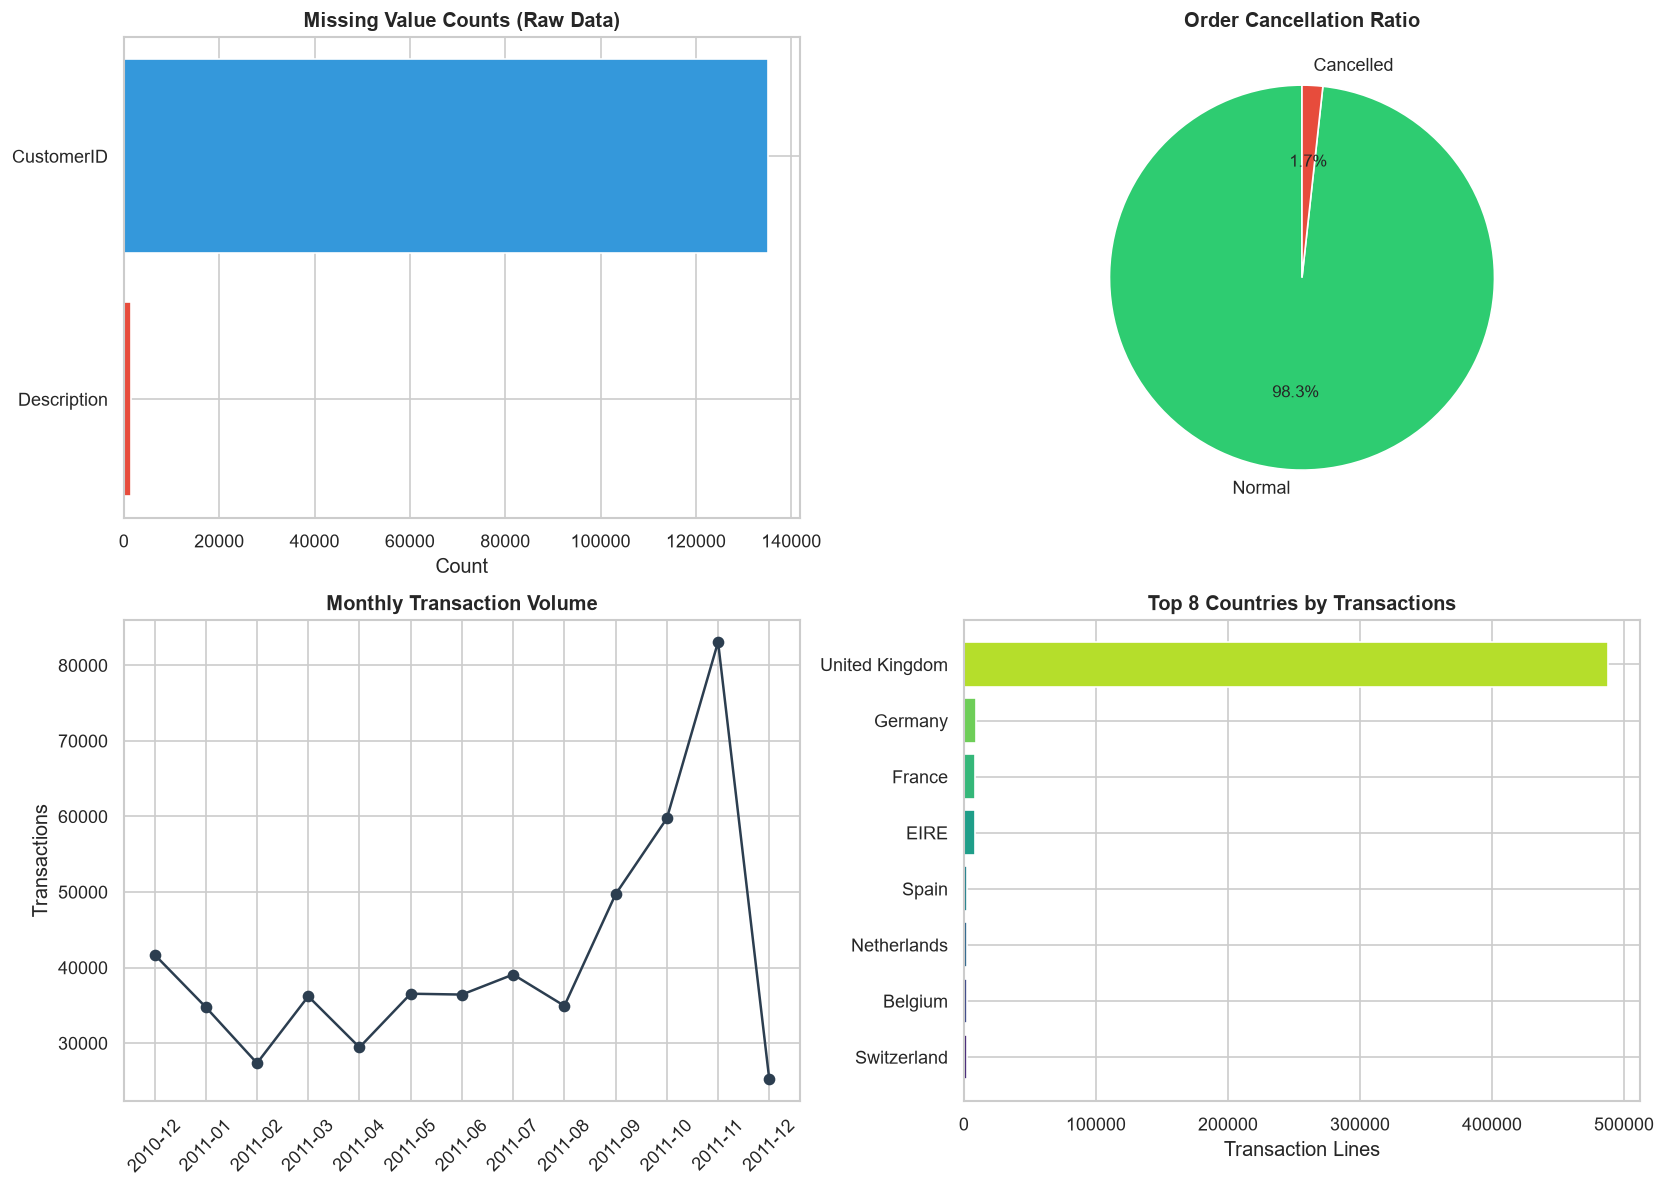

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Missing Values
mv = df_raw.isnull().sum()
mv = mv[mv > 0]
axes[0, 0].barh(mv.index, mv.values, color=["#e74c3c", "#3498db"])
axes[0, 0].set_title("Missing Value Counts (Raw Data)", fontweight="bold")
axes[0, 0].set_xlabel("Count")

# 2. Cancellations
can_counts = df_featured["IsCancellation"].value_counts()
axes[0, 1].pie(can_counts.values, labels=["Normal", "Cancelled"], colors=["#2ecc71", "#e74c3c"], autopct="%1.1f%%", startangle=90)
axes[0, 1].set_title("Order Cancellation Ratio", fontweight="bold")

# 3. Monthly Sales
monthly = df_featured.set_index("InvoiceDate").resample("ME").size()
axes[1, 0].plot(monthly.index.strftime("%Y-%m"), monthly.values, marker="o", color="#2c3e50")
axes[1, 0].set_title("Monthly Transaction Volume", fontweight="bold")
axes[1, 0].tick_params(axis="x", rotation=45)
axes[1, 0].set_ylabel("Transactions")

# 4. Top Countries
top_c = df_featured["Country"].value_counts().head(8)
axes[1, 1].barh(top_c.index[::-1], top_c.values[::-1], color=sns.color_palette("viridis", 8))
axes[1, 1].set_title("Top 8 Countries by Transactions", fontweight="bold")
axes[1, 1].set_xlabel("Transaction Lines")

plt.tight_layout()
plt.show()

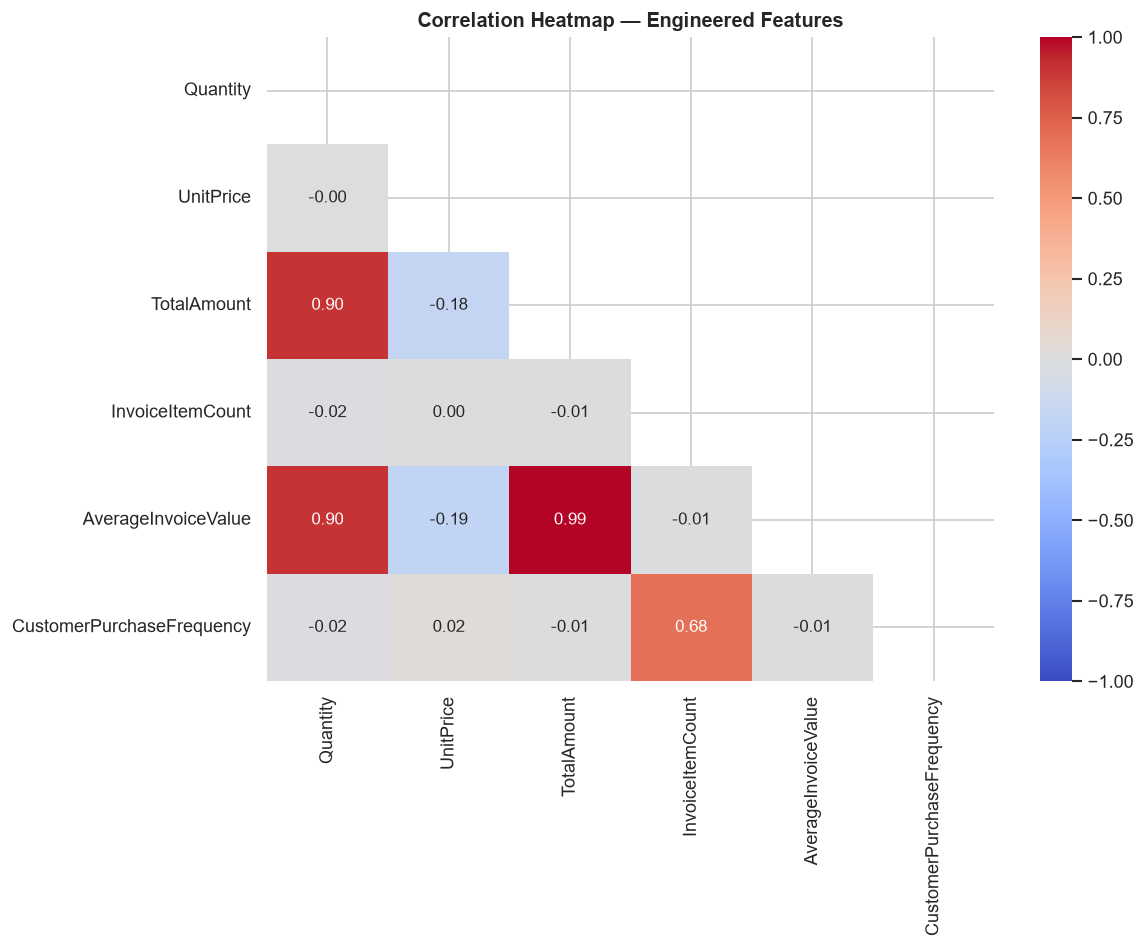

In [14]:
# Display Correlation Heatmap of Numeric Features
plt.figure(figsize=(10, 8))
num_cols = ["Quantity", "UnitPrice", "TotalAmount", "InvoiceItemCount", "AverageInvoiceValue", "CustomerPurchaseFrequency"]
corr = df_featured[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation Heatmap — Engineered Features", fontweight="bold")
plt.tight_layout()
plt.show()

## 18. Automated Scikit-Learn Preprocessing Pipeline

To prepare features for machine learning without **data leakage**, we:
1. Split data into train and test sets (80% / 20%).
2. Construct a `Pipeline` containing a `ColumnTransformer`:
   - **Numeric Transformer:** `SimpleImputer(strategy='median')` followed by `StandardScaler()`.
   - **Categorical Transformer:** `SimpleImputer(strategy='most_frequent')` followed by `OneHotEncoder(handle_unknown='ignore')`.
   - **Passthrough Transformer:** Preserves boolean and date-part columns.
3. Fit the pipeline **strictly on the training split**.
4. Transform test data and persist the trained model with `joblib`.

In [15]:
pipeline_results = train_test_pipeline_workflow(
    df_featured,
    test_size=0.2,
    random_state=42,
    pipeline_path=PIPELINE_FILE,
)

print(f"\nTrained Pipeline persisted to: {PIPELINE_FILE}")
print(f"Transformed X_train Shape: {pipeline_results['x_train'].shape}")
print(f"Transformed X_test Shape : {pipeline_results['x_test'].shape}")
print(f"Total Processed Features : {len(pipeline_results['feature_names'])}")
print("\nFirst 10 Engineered Model Feature Names:")
for i, name in enumerate(pipeline_results['feature_names'][:10], 1):
    print(f"  {i:2d}. {name}")


--- Train / Test Pipeline Workflow (Zero Data Leakage) ---


  Training set size : 427,303 rows (80%)
  Testing set size  : 106,826 rows (20%)


✅ Pipeline fitted and saved to E:\Awais_Document\Devixo Solution internship\Real-World Online Retail Data Cleaning & Feature Engineering\models\preprocessing_pipeline.joblib


  Transformed X_train shape: (427303, 65)
  Transformed X_test shape : (106826, 65)
  Total processed features : 65

Trained Pipeline persisted to: E:\Awais_Document\Devixo Solution internship\Real-World Online Retail Data Cleaning & Feature Engineering\models\preprocessing_pipeline.joblib
Transformed X_train Shape: (427303, 65)
Transformed X_test Shape : (106826, 65)
Total Processed Features : 65

First 10 Engineered Model Feature Names:
   1. num__Quantity
   2. num__UnitPrice
   3. num__TotalAmount
   4. num__InvoiceItemCount
   5. num__AverageInvoiceValue
   6. num__CustomerPurchaseFrequency
   7. cat__Country_Australia
   8. cat__Country_Austria
   9. cat__Country_Bahrain
  10. cat__Country_Belgium


## 19. Commercial Business Insights

We evaluate commercial performance metrics across products, countries, order sizes, and customer cohorts.

In [16]:
top_prods = get_top_products(df_featured, top_n=5)
print("=== TOP 5 PRODUCTS BY QUANTITY SOLD ===")
display(top_prods)

top_countries = get_top_countries(df_featured, top_n=5)
print("\n=== TOP 5 COUNTRIES BY REVENUE ===")
display(top_countries)

aov = calculate_average_order_value(df_featured)
print("\n=== BASKET SIZE & AVERAGE ORDER VALUE ===")
for k, v in aov.items():
    print(f"  {k:28s}: {v}")

freq = analyze_customer_frequency(df_featured)
print("\n=== CUSTOMER REPEAT FREQUENCY ===")
for k, v in freq.items():
    print(f"  {k:28s}: {v}")

pareto = analyze_revenue_distribution(df_featured)
print("\n=== PARETO (80/20) REVENUE CONCENTRATION ===")
for k, v in pareto.items():
    print(f"  {k:32s}: {v}")

=== TOP 5 PRODUCTS BY QUANTITY SOLD ===


,StockCode,Description,TotalQuantity,TotalRevenue,TransactionCount,AverageUnitPrice
0,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1,2.08
1,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,250,1.47
2,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951,13814.01,536,0.32
3,85099B,JUMBO BAG RED RETROSPOT,48371,94159.81,2109,2.49
4,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37580,104284.24,2244,3.12



=== TOP 5 COUNTRIES BY REVENUE ===


,Country,TransactionCount,TotalQuantity,TotalRevenue,UniqueCustomers,RevenueSharePct
0,United Kingdom,479985,4646906,9001744.09,3920,84.59
1,Germany,9025,119154,228678.40,94,2.15
2,France,8392,112060,209625.37,87,1.97
3,EIRE,7879,147007,283140.52,3,2.66
4,Spain,2479,27933,61558.56,30,0.58



=== BASKET SIZE & AVERAGE ORDER VALUE ===
  mean_aov                    : 533.17
  median_aov                  : 303.3
  std_aov                     : 1780.41
  min_order                   : 0.38
  max_order                   : 168469.6
  q25_aov                     : 151.7
  q75_aov                     : 493.46
  total_orders                : 19960

=== CUSTOMER REPEAT FREQUENCY ===
  total_known_customers       : 4371
  one_time_buyers             : 1312
  repeat_buyers               : 3059
  repeat_buyer_pct            : 69.98
  mean_orders_per_customer    : 5.08
  median_orders_per_customer  : 3.0
  max_orders_single_customer  : 248
  p75_orders_per_customer     : 5.0



=== PARETO (80/20) REVENUE CONCENTRATION ===
  customer_pareto_top_20pct_share : 74.68
  product_pareto_top_20pct_share  : 79.5
  total_revenue_evaluated         : 10642110.8


## 20. Final Dataset Validation

We execute automated validation assertions to confirm dataset integrity before persistence.

In [17]:
# Validation assertions
assert len(df_cleaned) == 534129, f"Expected 534,129 cleaned rows, got {len(df_cleaned):,}"
assert (df_cleaned['UnitPrice'] <= 0).sum() == 0, "Cleaned dataset contains invalid prices"
assert df_cleaned.duplicated().sum() == 0, "Cleaned dataset contains duplicate rows"
assert len(df_featured.columns) == 22, f"Expected 22 columns in featured dataset, got {len(df_featured.columns)}"
assert PIPELINE_FILE.exists(), "Trained pipeline file does not exist"

print("✅ ALL FINAL DATASET VALIDATION CHECKS PASSED SUCCESSFULLY!")

✅ ALL FINAL DATASET VALIDATION CHECKS PASSED SUCCESSFULLY!


## 21. Conclusion & Key Takeaways

### Summary of Achievements:
1. **Preserved Commercial Reality:** Instead of blindly deleting records with negative quantities or missing `CustomerID`, we categorized cancellations and distinguished legitimate guest checkouts from data corruption.
2. **Noise Elimination:** Successfully eliminated 5,268 exact duplicates and 2,512 non-commercial invalid price transactions (bad debts and zero-price inventory adjustments).
3. **High-Value Feature Engineering:** Engineered 14 domain features spanning monetary totals, temporal attributes, order flags, and customer-level aggregations.
4. **Production Preprocessing Pipeline:** Built an automated, leakage-free Scikit-Learn `ColumnTransformer` pipeline that handles scaling, missing values, and one-hot encoding for 65 processed features.
5. **Commercial Intelligence:** Revealed that 69.98% of identified customers are repeat buyers and that the top 20% of customers generate 74.68% of total revenue (£10.64M gross sales).

---
**Project Author:** Muhammad Awais Bacha  
**Organization:** Devixo Solutions  
**Status:** Task 02 Completed Successfully